In [1]:
import cuml

from cuml.ensemble import RandomForestRegressor

from sklearn import ensemble
from sklearn.ensemble import ExtraTreesRegressor

import sklearn

import matplotlib.pyplot as plt

import xgboost as xgb
from lightgbm import LGBMRegressor

import torch

import numpy as np
import cupy as cp

import pandas as pd
from pathlib import Path
import gc

from sklearn.metrics import r2_score

import time

In [2]:
randomf = True
extrat = True
xgboost = True
lgboostm = True

In [3]:
modelsLib = {
    "rf": 1,
    "rfGPU": 1,
    "et": 1,
    "etGPU": 1,
    "xgb": 1,
    "xgbGPU": 1,
    "lgbm": 1,
    "lgbmGPU": 1
}

In [4]:
RF = {
    "model": RandomForestRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [24, 24, 1],
    "n_bins": [256, 256, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": [],
    "trials": []
}

ET = {
    "model": ExtraTreesRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [21, 21, 1],
    "min_samples_leaf": [4, 4, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": []
}

X = {
    "model": xgb,
    "n_estimators": [500, 500, 50],
    "max_depth": [15, 15, 1],
    "min_child_weight": [3, 3, 1],
    "results": []
}

LGBM = {
    "model": LGBMRegressor,
    "n_estimators": [450, 450, 50],
    "min_child_samples": [15, 15, 10],
    "num_leaves": [256, 256, 2],
    "colsample_bytree": [0.7, 0.7, 0.1],
    "results": [],
    "trials": []
}

In [5]:
datasetPath = Path("/home/philipm/Desktop/ML-For-CV-Robustness/datasets/trees-dl-aoi.csv")

#making sure
datasetPath.is_file()

True

In [6]:
dataset = pd.read_csv(datasetPath)
dataset.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw,grviOut
0,0.210754,0.000179,0.000229,1136.471,1031.228,0.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.116122
1,0.123970,0.000280,0.000321,1136.471,1031.228,1.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.106717
2,0.092202,0.000341,0.000383,1136.471,1031.228,2.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.097078
3,0.191730,0.000242,0.000306,1136.471,1031.228,3.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.112769
4,0.145418,0.000262,0.000312,1136.471,1031.228,4.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.103993


In [7]:
target_col = dataset["grviOut"]
labels = target_col.to_numpy(dtype="float32")
labels

array([0.1161218 , 0.10671729, 0.09707835, ..., 0.13551866, 0.13556816,
       0.14273934], shape=(333760,), dtype=float32)

In [8]:
inputs = dataset.drop("grviOut", axis=1)
inputs = inputs.drop("sunRoll", axis=1)
inputs = inputs.drop("camRoll", axis=1)

inputs.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunPitch,sunYaw,camPitch,camYaw
0,0.210754,0.000179,0.000229,1136.471,1031.228,0.0,-71.945084,19.489212,-19.258,-0.0
1,0.123970,0.000280,0.000321,1136.471,1031.228,1.0,-71.945084,19.489212,-19.258,-0.0
2,0.092202,0.000341,0.000383,1136.471,1031.228,2.0,-71.945084,19.489212,-19.258,-0.0
3,0.191730,0.000242,0.000306,1136.471,1031.228,3.0,-71.945084,19.489212,-19.258,-0.0
4,0.145418,0.000262,0.000312,1136.471,1031.228,4.0,-71.945084,19.489212,-19.258,-0.0


In [9]:
inputs = inputs.to_numpy(dtype="float32")
inputs

array([[ 2.1075405e-01,  1.7945077e-04,  2.2896443e-04, ...,
         1.9489212e+01, -1.9257999e+01, -0.0000000e+00],
       [ 1.2397036e-01,  2.7967661e-04,  3.2067925e-04, ...,
         1.9489212e+01, -1.9257999e+01, -0.0000000e+00],
       [ 9.2202291e-02,  3.4122023e-04,  3.8319931e-04, ...,
         1.9489212e+01, -1.9257999e+01, -0.0000000e+00],
       ...,
       [ 2.3046868e-01,  1.0813908e-03,  1.6539922e-03, ...,
         1.0435840e+02, -2.2218000e+01, -1.8000000e+02],
       [ 2.3434559e-01,  9.0364768e-04,  1.3691875e-03, ...,
         1.0435840e+02, -2.2218000e+01, -1.8000000e+02],
       [ 2.4411118e-01,  8.7809877e-04,  1.3535006e-03, ...,
         1.0435840e+02, -2.2218000e+01, -1.8000000e+02]],
      shape=(333760, 10), dtype=float32)

In [10]:
n_total = len(inputs)

n_train = int(0.9*n_total)
n_val = int(0.1*n_total)

# shuffle
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n_total, generator=g).numpy()

inputs_shuf = inputs[perm]
labels_shuf = labels[perm]

# split
train_inputs, train_labels = inputs_shuf[:n_train], labels_shuf[:n_train]
val_inputs, val_labels = inputs_shuf[n_train:n_train + n_val], labels_shuf[n_train:n_train + n_val]

7.057559967041016%
r2: 0.8131389617919922
rmse: 0.011410946211964342


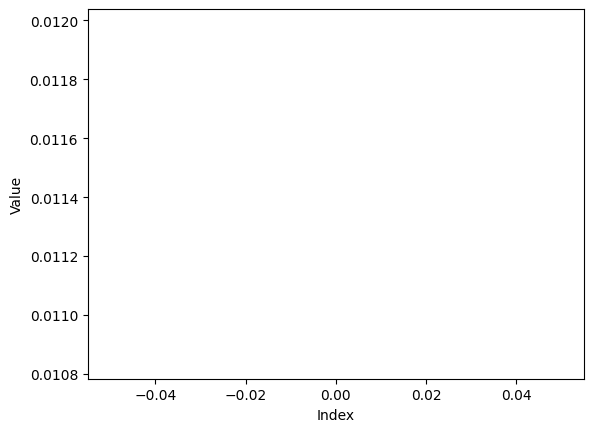

In [11]:
# RF
# starting point
if randomf:
    
    ne = RF["n_estimators"][0]
    md = RF["max_depth"][0]
    nb = RF["n_bins"][0]
    mf = RF["max_features"][0]
    
    while True:
        if ne > RF["n_estimators"][1]:
            ne = RF["n_estimators"][0]
            break
    
        while True:
            if md > RF["max_depth"][1]:
                md = RF["max_depth"][0]
                break
    
            while True:
                if nb > RF["n_bins"][1]:
                    nb = RF["n_bins"][0]
                    break
    
                while True:
                    if mf > RF["max_features"][1]:
                        mf = RF["max_features"][0]
                        break
    
                    modelrfGPU = RF["model"](n_estimators=ne, max_depth=md, n_bins=nb, max_features=mf)
                    modelrfGPU.fit(train_inputs, train_labels)
    
                    y_pred = modelrfGPU.predict(val_inputs)
                    modelsLib["rfGPU"] = modelrfGPU
                    
                    mse = cuml.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = cp.sqrt(mse)
    
                    RF["results"].append(float(rmse))
                    RF["trials"].append({
                        "n_estimators": ne,
                        "max_depth": md,
                        "n_bins": nb,
                        "max_features": mf,
                        "rmse": float(rmse)
                    })
    
                    mf = mf + RF["max_features"][2]
    
                nb = nb * RF["n_bins"][2]
    
            md = md + RF["max_depth"][2]
    
        ne = ne+ RF["n_estimators"][2]

    
    r2 = r2_score(val_labels, y_pred)
    rel_test_loss = min(RF["results"])*100 / (val_labels.max()-val_labels.min())
    print(str(float(rel_test_loss)) + "%")
    print ("r2: " + str(r2))
    print ("rmse: " + str(rmse))
    


    plt.plot(range(len(RF["results"])), RF["results"])
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.show()

In [12]:
modelrf = ensemble.RandomForestRegressor(n_estimators=ne, max_depth=md, max_features=mf)
modelrf.fit(train_inputs, train_labels)

y_pred = modelrf.predict(val_inputs)
modelsLib["rf"] = modelrf

mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
rmse = cp.sqrt(mse)


r2 = r2_score(val_labels, y_pred)
rel_test_loss = (rmse*100) / (val_labels.max()-val_labels.min())
print(str(float(rel_test_loss)) + "%")
print ("r2: " + str(r2))
print ("rmse: " + str(rmse))

6.7473424115454605%
r2: 0.8292050649296521
rmse: 0.010909373540059508


5.102850437164307%
r2: 0.9023133594232347
rmse: 0.008250493108924162


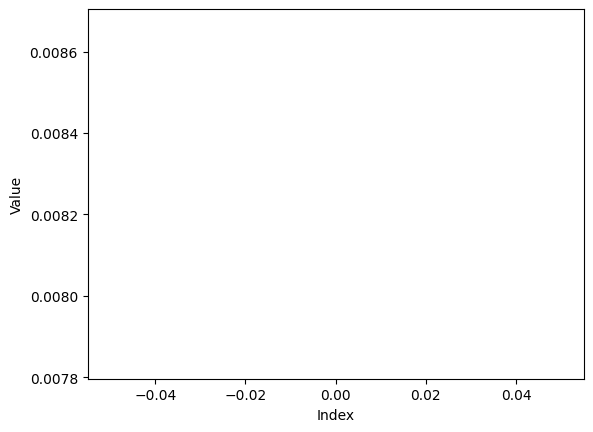

In [13]:
# ET
# starting point

if extrat:

    ne = ET["n_estimators"][0]
    md = ET["max_depth"][0]
    nb = ET["min_samples_leaf"][0]
    mf = ET["max_features"][0]
    
    while True:
        if ne > ET["n_estimators"][1]:
            ne = ET["n_estimators"][0]
            break
    
        while True:
            if md > ET["max_depth"][1]:
                md = ET["max_depth"][0]
                break
    
            while True:
                if nb > ET["min_samples_leaf"][1]:
                    nb = ET["min_samples_leaf"][0]
                    break
    
                while True:
                    if mf > ET["max_features"][1]:
                        mf = ET["max_features"][0]
                        break
    
                    modelET = ET["model"](n_estimators=ne, max_depth=md, min_samples_leaf=nb, max_features=mf)
                    modelET.fit(train_inputs, train_labels)
    
                    y_pred = modelET.predict(val_inputs)

                    modelsLib["et"] = modelET
                    
                    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = np.sqrt(mse)
    
                    ET["results"].append(float(rmse))
    
                    mf = mf + ET["max_features"][2]
    
                nb = nb * ET["min_samples_leaf"][2]
    
            md = md + ET["max_depth"][2]
    
        ne = ne+ ET["n_estimators"][2]
    
        rel_test_loss = min(ET["results"])*100 / (val_labels.max()-val_labels.min())
        print(str(float(rel_test_loss)) + "%")


        r2 = r2_score(val_labels, y_pred)
        print ("r2: " + str(r2))
        print ("rmse: " + str(rmse))
        
        plt.plot(range(len(ET["results"])), ET["results"])
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.show()

In [14]:
# make ET fast
from cuml import ForestInference

if extrat:
    
    y_pred = modelET.predict(val_inputs)
    
    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
    rmse = np.sqrt(mse)
    
    rel_test_loss = rmse*100 / (val_labels.max()-val_labels.min())
    print("unoptimized ET:" + str(float(rel_test_loss)) + "%")


    fil_model_ET = ForestInference.load_from_sklearn(modelET)
    modelsLib["etGPU"] = fil_model_ET
    
    val_inputs_gpu = cp.asarray(val_inputs, dtype=cp.float32)
    y_pred_gpu = fil_model_ET.predict(val_inputs_gpu)

    mse = cuml.metrics.mean_squared_error(val_labels, y_pred_gpu)
    rmse = cp.sqrt(mse)

    print("optimized ET:" + str(float(rel_test_loss)) + "%")

unoptimized ET:5.102850485922944%
optimized ET:5.102850485922944%


4.680222034454346%
r2: 0.9178245067596436
rmse: 0.007567170072755924


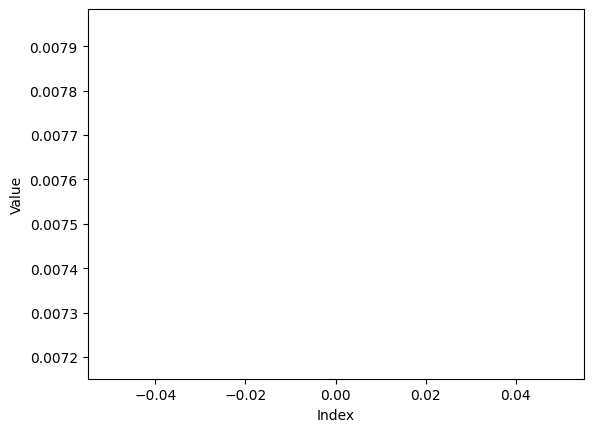

In [15]:
# XGB
# starting point

if xgboost:

    ne = X["n_estimators"][0]
    md = X["max_depth"][0]
    mc = X["min_child_weight"][0]
    
    while True:
        if ne > X["n_estimators"][1]:
            ne = X["n_estimators"][0]
            break
    
        while True:
            if md > X["max_depth"][1]:
                md = X["max_depth"][0]
                break
    
            while True:
                if mc > X["min_child_weight"][1]:
                    mc = X["min_child_weight"][0]
                    break
    
                modelXGB = X["model"].XGBRegressor(n_estimators=ne, max_depth=md, min_child_weight=mc, learning_rate=0.05, tree_method="gpu_hist", gpu_id=0)
                modelXGB.fit(train_inputs, train_labels)

                y_pred = modelXGB.predict(val_inputs)

                modelsLib["xgb"] = modelXGB

                mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                rmse = np.sqrt(mse)

                X["results"].append(float(rmse))
    
                mc = mc + X["min_child_weight"][2]
    
            md = md + X["max_depth"][2]
    
        ne = ne+ X["n_estimators"][2]
    
        rel_test_loss = min(X["results"])*100 / (val_labels.max()-val_labels.min())
        print(str(float(rel_test_loss)) + "%")


        r2 = r2_score(val_labels, y_pred)
        print ("r2: " + str(r2))
        print ("rmse: " + str(rmse))
        
        plt.plot(range(len(X["results"])), X["results"])
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.show()

In [16]:
if xgboost:
    model_path = "best_xgb.json"
    modelXGB.save_model(model_path)

    fil_model_xgb = ForestInference.load(model_path, model_type="xgboost_json")
    modelsLib["xgbGPU"] = fil_model_xgb

    val_inputs_gpu = cp.asarray(val_inputs, dtype=cp.float32)
    y_pred_gpu = fil_model_xgb.predict(val_inputs_gpu)

    mse = cuml.metrics.mean_squared_error(val_labels, y_pred_gpu)
    rmse = cp.sqrt(mse)

    print("optimized XGB:" + str(float(rel_test_loss)) + "%")

optimized XGB:4.680222034454346%


In [17]:
if lgboostm:

    ne = LGBM["n_estimators"][0]
    mcs = LGBM["min_child_samples"][0]
    nl = LGBM["num_leaves"][0]
    cb = LGBM["colsample_bytree"][0]
    
    while True:
        if ne > LGBM["n_estimators"][1]:
            ne = LGBM["n_estimators"][0]
            break
    
        while True:
            if mcs > LGBM["min_child_samples"][1]:
                mcs = LGBM["min_child_samples"][0]
                break
    
            while True:
                if nl > LGBM["num_leaves"][1]:
                    nl = LGBM["num_leaves"][0]
                    break
    
                while True:
                    if cb > LGBM["colsample_bytree"][1]:
                        cb = LGBM["colsample_bytree"][0]
                        break
    
                    modelLGBM = LGBM["model"](n_estimators=ne, min_child_samples=mcs, num_leaves=nl-1, colsample_bytree=cb)
                    modelLGBM.fit(train_inputs, train_labels)
    
                    y_pred = modelLGBM.predict(val_inputs)

                    modelsLib["lgbm"] = modelLGBM
                    
                    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = np.sqrt(mse)
    
                    LGBM["results"].append(float(rmse))

                    LGBM["trials"].append({
                        "n_estimators": ne,
                        "min_child_samples": mcs,
                        "num_leaves": nl,
                        "colsample_bytree": cb,
                        "rmse": float(rmse)
                    })
    
                    cb = round(cb + LGBM["colsample_bytree"][2], 1)
    
                nl = nl * LGBM["num_leaves"][2]
    
            mcs = mcs + LGBM["min_child_samples"][2]
    
        ne = ne + LGBM["n_estimators"][2]
    
    rel_test_loss = min(LGBM["results"])*100 / (val_labels.max()-val_labels.min())
    print(str(float(rel_test_loss)) + "%")


    r2 = r2_score(val_labels, y_pred)
    print ("r2: " + str(r2))
    print ("rmse: " + str(rmse))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007203 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1636
[LightGBM] [Info] Number of data points in the train set: 300384, number of used features: 10
[LightGBM] [Info] Start training from score 0.155433
5.1486945152282715%
r2: 0.9005502259631895
rmse: 0.008324616183264502


In [18]:
modelLGBM.booster_.save_model("lgbm_model.txt")

fil_model_LGBM = ForestInference.load(
    "lgbm_model.txt",
    model_type="lightgbm",
    is_classifier=False,
    output_type="cupy"
)

modelsLib["lgbmGPU"] = fil_model_LGBM

X_test_gpu = cp.asarray(
    np.asarray(val_inputs, dtype=np.float32)
)

pred_gpu = fil_model_LGBM.predict(X_test_gpu)

val_inputs_gpu = cp.asarray(val_inputs, dtype=cp.float32)

mse = cuml.metrics.mean_squared_error(val_labels, pred_gpu)
rmse = cp.sqrt(mse)

print("optimized LGBM:" + str(float(rel_test_loss)) + "%")

optimized LGBM:5.1486945152282715%


In [19]:
from sklearn.inspection import permutation_importance

In [20]:
column_names = ["grviIn", "meanRefR", "meanRefG", "illumR", "illumG", "blockIdx", "sunPitch", "sunYaw", "camPitch", "camYaw"]
df = pd.DataFrame(val_inputs, columns=column_names)

In [26]:
model = modelsLib["et"]

X_val = df
y_val = val_labels  

result = permutation_importance(
    estimator=model,
    X=X_val,
    y=y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

# Feature names
feature_names = (
    X_val.columns.tolist()
    if isinstance(X_val, pd.DataFrame)
    else [f"Feature {i}" for i in range(X_val.shape[1])]
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean,
    "std": result.importances_std
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

print(importance_df)

/home/philipm/miniconda3/envs/hls4ml-tutorial/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but ExtraTreesRegressor was fitted without feature names
  warnings.warn(
/home/philipm/miniconda3/envs/hls4ml-tutorial/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but ExtraTreesRegressor was fitted without feature names
  warnings.warn(
/home/philipm/miniconda3/envs/hls4ml-tutorial/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but ExtraTreesRegressor was fitted without feature names
  warnings.warn(
/home/philipm/miniconda3/envs/hls4ml-tutorial/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but ExtraTreesRegressor was fitted without feature names
  warnings.warn(
/home/philipm/miniconda3/envs/hls4ml-tutorial/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feat

    feature  importance       std
8  camPitch    0.019494  0.000053
9    camYaw    0.015329  0.000056
5  blockIdx    0.006693  0.000104
0    grviIn    0.002831  0.000049
2  meanRefG    0.001690  0.000022
1  meanRefR    0.001666  0.000015
7    sunYaw    0.000822  0.000015
4    illumG    0.000697  0.000011
6  sunPitch    0.000640  0.000018
3    illumR    0.000571  0.000009


In [27]:
importance_df.to_csv("/home/philipm/Desktop/et-importance-trees-dl-aoi.csv")